# Lesson 6 · Seeing Your Data: Matplotlib
### Line, bar, histogram, scatter and box plots: and how to make charts that tell the truth

| | |
|---|---|
| **Type** | LESSON 06 |
| **Time** | about 120 minutes |
| **Level** | Beginner → Intermediate |
| **Prerequisites** | Lessons 3–5 |

**By the end of this notebook you will be able to:**

- Explain why we *always* plot, using Anscombe's quartet
- Use the object-oriented Matplotlib interface: `fig, ax = plt.subplots()`
- Draw line, bar, histogram, scatter and box plots from pandas data
- Customise titles, labels, legends, annotations, shaded regions and date axes
- Build multi-panel figures, dual-axis charts and save to file
- Choose the right chart for a question, and spot misleading charts

## 🛠️ Setup
Run this cell first. It imports the tools and loads the data every problem below relies on.

In [1]:

import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from course_utils import DATA_DIR, check, check_plot

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False})

prices = pd.read_csv(DATA_DIR / "market_prices_clean.csv", parse_dates=["date"])
prices["year"] = prices["date"].dt.year
prices["month"] = prices["date"].dt.month
print("Setup complete ✔  prices:", prices.shape)


Setup complete ✔  prices: (15048, 11)


## 👋 A picture is worth a thousand rows

In the last three lessons we computed means, medians, correlations. Numbers *summarise*; pictures *reveal*. Before I teach you a single plotting command, let me show you why no analyst should ever skip the picture.

### Anscombe's quartet (1973)

Four small datasets. Compute the usual summary statistics for each…

In [2]:
x123 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
sets = {
    "I":   (x123, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "II":  (x123, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "III": (x123, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "IV":  ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
for name, (x, y) in sets.items():
    x, y = np.array(x), np.array(y)
    print(f"{name:>3}: mean(x)={x.mean():.2f}  mean(y)={y.mean():.2f}  var(y)={y.var(ddof=1):.2f}  corr={np.corrcoef(x, y)[0,1]:.3f}")

  I: mean(x)=9.00  mean(y)=7.50  var(y)=4.13  corr=0.816
 II: mean(x)=9.00  mean(y)=7.50  var(y)=4.13  corr=0.816
III: mean(x)=9.00  mean(y)=7.50  var(y)=4.12  corr=0.816
 IV: mean(x)=9.00  mean(y)=7.50  var(y)=4.12  corr=0.817


Identical, to two decimal places. Four datasets, one summary. **Now plot them:**

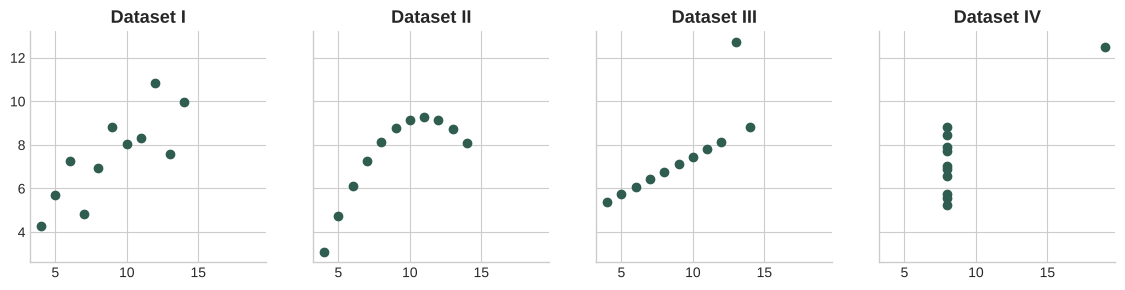

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharex=True, sharey=True)
for ax, (name, (x, y)) in zip(axes, sets.items()):
    ax.scatter(x, y, color="#2F5D50")
    ax.set_title(f"Dataset {name}")
plt.show()

> 💡 **Intuition.** One is a neat noisy line, one is a perfect curve, one has an outlier dragging the fit, and one is a vertical stack with a single leverage point. Summary statistics **cannot tell these apart; your eyes can in one second.** Always plot.

## 1 · The anatomy of a Matplotlib chart

```
┌─────────────────────── Figure ────────────────────────┐   Figure = the whole canvas (the "paper")
│  ┌───────────────────── Axes ──────────────────────┐  │   Axes   = one plot (data area + axes + labels)
│  │   Title                                         │  │   Axis   = the x or y ruler
│  │ y-label                                         │  │
│  │   │   ●  line / bars / points  ← "artists"      │  │
│  │   └───────────────── x-label                    │  │
│  └─────────────────────────────────────────────────┘  │
└────────────────────────────────────────────────────────┘
```

There are two ways to use Matplotlib:

| Style | Looks like | Verdict |
|---|---|---|
| **pyplot (state-machine)** | `plt.plot(x, y); plt.title("..")` | quick for one-offs, confusing with several plots |
| **Object-oriented** | `fig, ax = plt.subplots(); ax.plot(x, y); ax.set_title("..")` | ✅ **use this**: explicit about *which* chart you're editing |

Our recipe, always:

1. `fig, ax = plt.subplots(figsize=(w, h))`: make the canvas and the axes.
2. `ax.<plot-type>(...)`: draw data.
3. `ax.set_title / set_xlabel / set_ylabel / legend`: explain it.
4. `plt.show()` (or `fig.savefig`).

## 2 · Line plots: change over time

Our question: *how did the tomato price at Wakulima Market move?*

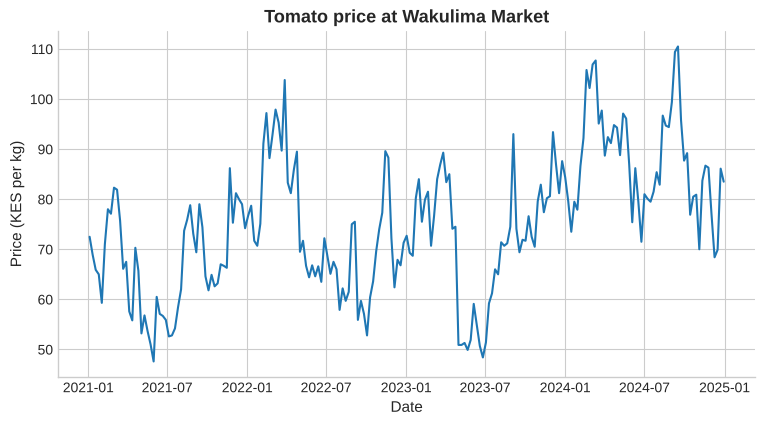

In [4]:
tom = prices[(prices["crop"] == "Tomatoes") & (prices["market"] == "Wakulima Market")].sort_values("date")

fig, ax = plt.subplots()
ax.plot(tom["date"], tom["price_kes_per_kg"])
ax.set_title("Tomato price at Wakulima Market")
ax.set_xlabel("Date")
ax.set_ylabel("Price (KES per kg)")
plt.show()

Good start. Now let's upgrade it: smoother line, markers, a moving average, a shaded **drought period**, an **annotation** on the peak, a legend, a yearly date axis.

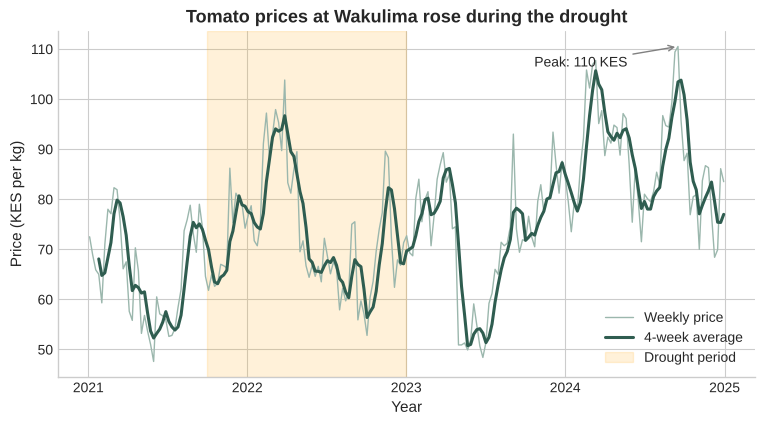

In [5]:
tom = tom.assign(ma4=tom["price_kes_per_kg"].rolling(4).mean())

fig, ax = plt.subplots()
ax.plot(tom["date"], tom["price_kes_per_kg"], color="#9bb7ad", linewidth=1, label="Weekly price")
ax.plot(tom["date"], tom["ma4"], color="#2F5D50", linewidth=2.2, label="4-week average")

ax.axvspan(pd.Timestamp("2021-10-01"), pd.Timestamp("2022-12-31"), color="orange", alpha=0.15, label="Drought period")

peak = tom.loc[tom["price_kes_per_kg"].idxmax()]
ax.annotate(f"Peak: {peak['price_kes_per_kg']:.0f} KES", xy=(peak["date"], peak["price_kes_per_kg"]),
            xytext=(peak["date"] - pd.Timedelta(days=330), peak["price_kes_per_kg"] - 4),
            arrowprops=dict(arrowstyle="->", color="grey"))

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Tomato prices at Wakulima rose during the drought")
ax.set_xlabel("Year")
ax.set_ylabel("Price (KES per kg)")
ax.legend(frameon=False)
plt.show()

> 💡 **Intuition.** A good title states the **finding**, not just the topic: *“Tomato prices rose during the drought”* beats *“Tomato price over time.”* The reader should know what to look at before they look.

**Several lines.** Loop over groups and add a `label` to each; call `ax.legend()` once at the end.

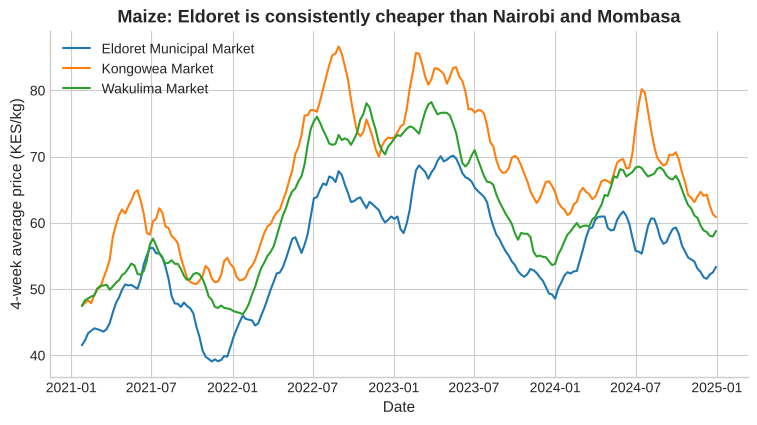

In [6]:
fig, ax = plt.subplots()
for market, g in prices[prices["crop"] == "Maize"].groupby("market"):
    if market in ["Wakulima Market", "Kongowea Market", "Eldoret Municipal Market"]:
        g = g.sort_values("date")
        ax.plot(g["date"], g["price_kes_per_kg"].rolling(4).mean(), label=market)
ax.set_title("Maize: Eldoret is consistently cheaper than Nairobi and Mombasa")
ax.set_xlabel("Date"); ax.set_ylabel("4-week average price (KES/kg)")
ax.legend()
plt.show()

> ⚠️ **Common mistake.** A line implies the points are **connected in order** (time). Never use a line plot for unordered categories (like crops): use bars. And always **sort by date** before plotting, or the line will zig-zag across the chart.

## 3 · Bar charts: comparing categories

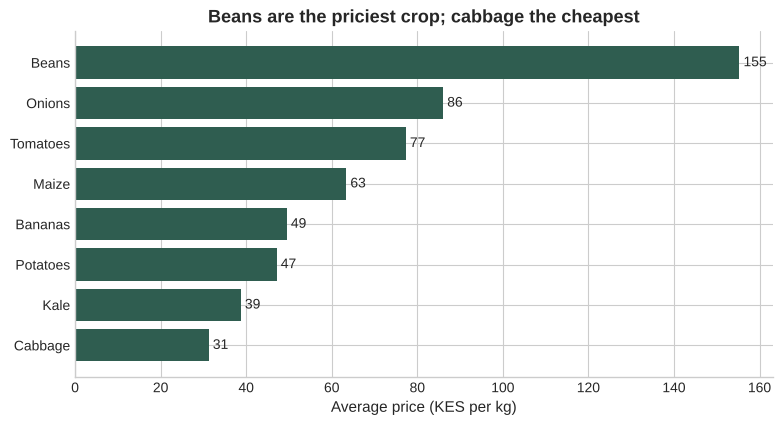

In [7]:
avg = prices.groupby("crop")["price_kes_per_kg"].mean().sort_values()

fig, ax = plt.subplots()
bars = ax.barh(avg.index, avg.values, color="#2F5D50")        # barh = horizontal: long names stay readable
ax.bar_label(bars, fmt="%.0f", padding=3)                      # value labels
ax.set_title("Beans are the priciest crop; cabbage the cheapest")
ax.set_xlabel("Average price (KES per kg)")
plt.show()

**Grouped bars** compare two series side by side: place the bars at shifted x positions.

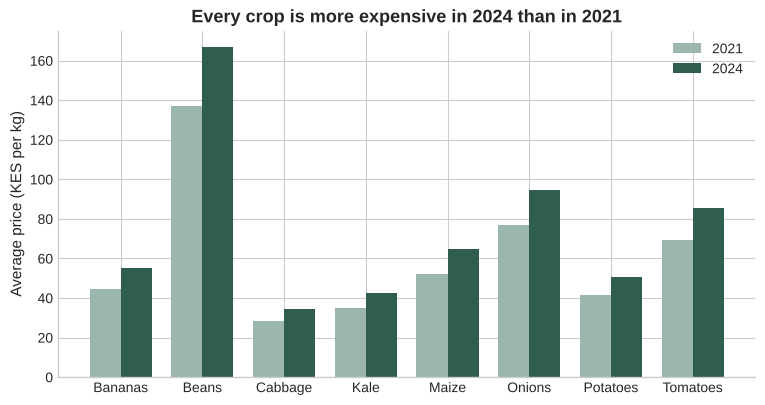

In [8]:
yp = prices.pivot_table(index="crop", columns="year", values="price_kes_per_kg", aggfunc="mean")[[2021, 2024]]
x = np.arange(len(yp)); w = 0.38

fig, ax = plt.subplots()
ax.bar(x - w/2, yp[2021], w, label="2021", color="#9bb7ad")
ax.bar(x + w/2, yp[2024], w, label="2024", color="#2F5D50")
ax.set_xticks(x); ax.set_xticklabels(yp.index)
ax.set_title("Every crop is more expensive in 2024 than in 2021")
ax.set_ylabel("Average price (KES per kg)")
ax.legend()
plt.show()

> ⚠️ **Common mistake.** **Bar charts must start at zero.** Bar *length* encodes the value; chopping the axis exaggerates differences. (Line and scatter plots may zoom, because they encode position, not length.)

## 4 · Histograms: the shape of one variable

*How are prices distributed? Is there a typical value, a long tail, two humps?*

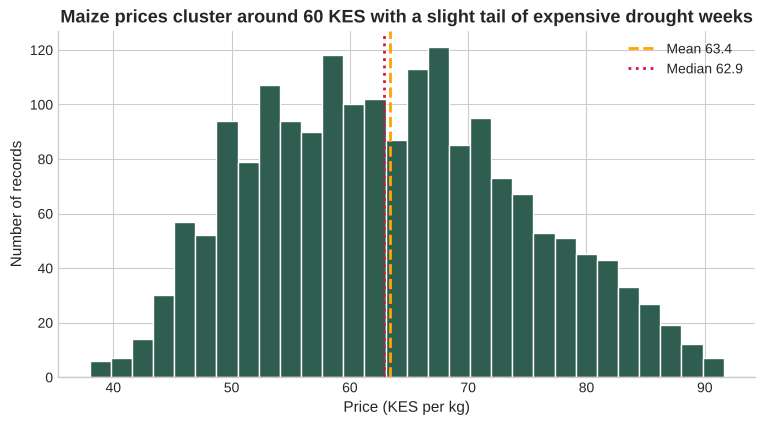

In [9]:
mz = prices.loc[prices["crop"] == "Maize", "price_kes_per_kg"]

fig, ax = plt.subplots()
ax.hist(mz, bins=30, color="#2F5D50", edgecolor="white")
ax.axvline(mz.mean(), color="orange", linestyle="--", linewidth=2, label=f"Mean {mz.mean():.1f}")
ax.axvline(mz.median(), color="crimson", linestyle=":", linewidth=2, label=f"Median {mz.median():.1f}")
ax.set_title("Maize prices cluster around 60 KES with a slight tail of expensive drought weeks")
ax.set_xlabel("Price (KES per kg)"); ax.set_ylabel("Number of records")
ax.legend()
plt.show()

> 🧠 **Pause and predict.** The mean sits just to the **right** of the median. What would a *large* gap tell you? (A few very high values pull the mean up while the median resists them; mean > median signals right-skew. Here the gap is small, so the skew is mild; a good reminder to **read the picture, not just the rule**.)

> 💡 **Intuition.** **Bins matter.** Too few and you hide structure; too many and you see noise. Try 10, 30, 80 and pick the one that shows the shape without jitter. A good start: `bins='auto'` or the *Freedman–Diaconis* rule `bins='fd'`.

Comparing two groups: overlay with transparency (or use `density=True` when group sizes differ).

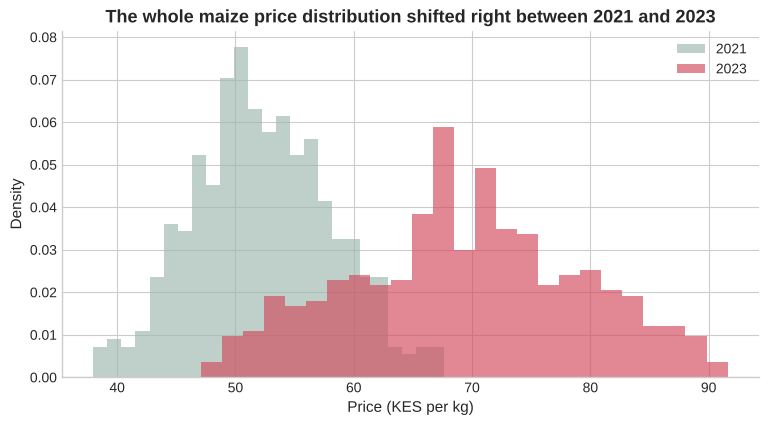

In [10]:
fig, ax = plt.subplots()
for yr, color in [(2021, "#9bb7ad"), (2023, "#d1495b")]:
    ax.hist(prices.loc[(prices["crop"] == "Maize") & (prices["year"] == yr), "price_kes_per_kg"],
            bins=25, alpha=0.65, density=True, label=str(yr), color=color)
ax.set_title("The whole maize price distribution shifted right between 2021 and 2023")
ax.set_xlabel("Price (KES per kg)"); ax.set_ylabel("Density")
ax.legend()
plt.show()

## 5 · Scatter plots: relationships between two numbers

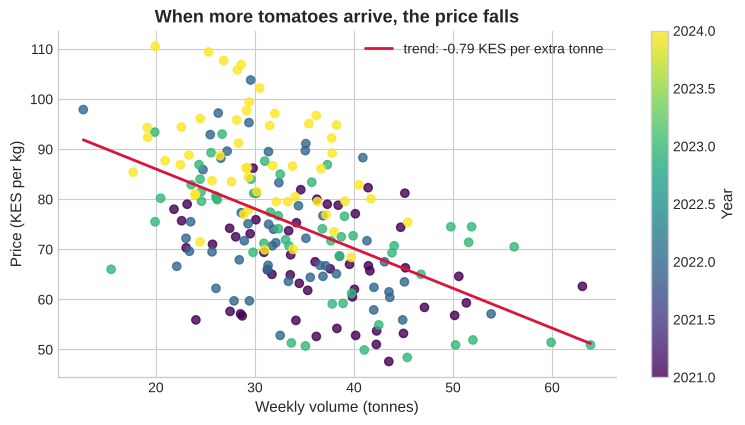

correlation: -0.51


In [11]:
t = prices[(prices["crop"] == "Tomatoes") & (prices["market"] == "Wakulima Market")]

fig, ax = plt.subplots()
sc = ax.scatter(t["volume_kg"] / 1000, t["price_kes_per_kg"], c=t["year"], cmap="viridis", alpha=0.8)
slope, intercept = np.polyfit(t["volume_kg"] / 1000, t["price_kes_per_kg"], 1)          # a straight-line fit
xs = np.linspace((t["volume_kg"] / 1000).min(), (t["volume_kg"] / 1000).max(), 50)
ax.plot(xs, intercept + slope * xs, color="crimson", linewidth=2, label=f"trend: {slope:.2f} KES per extra tonne")
fig.colorbar(sc, ax=ax, label="Year")
ax.set_title("When more tomatoes arrive, the price falls")
ax.set_xlabel("Weekly volume (tonnes)"); ax.set_ylabel("Price (KES per kg)")
ax.legend()
plt.show()
print("correlation:", round(t["volume_kg"].corr(t["price_kes_per_kg"]), 2))

> ⚠️ **Common mistake.** **Overplotting:** with thousands of points a scatter becomes a blob. Use `alpha=0.2`, smaller markers (`s=8`), a random sample, or a hexbin/2D histogram. And remember: a trend line shows association, **not causation**.

## 6 · Box plots: compare distributions at a glance

```
         ┌──────┐        ← Q3 (75th percentile)
   ──────┤      ├──────   whiskers reach the furthest point within 1.5 × IQR
         │──────│        ← median
         └──────┘        ← Q1 (25th percentile)
    ○                    ← dots beyond the whiskers: potential outliers
```

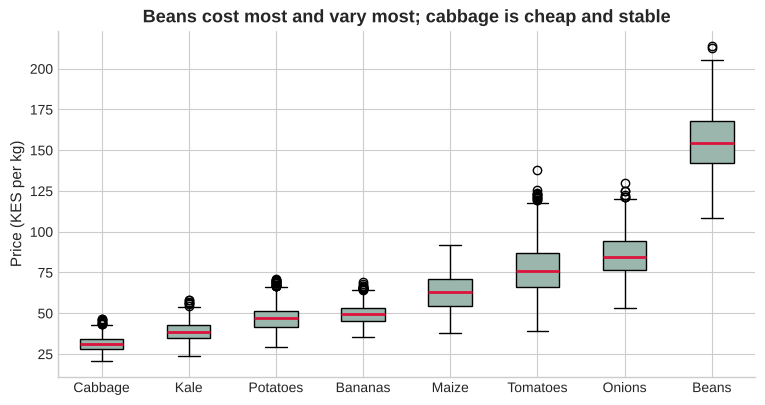

In [12]:
order = prices.groupby("crop")["price_kes_per_kg"].median().sort_values().index
data = [prices.loc[prices["crop"] == c, "price_kes_per_kg"] for c in order]

fig, ax = plt.subplots()
ax.boxplot(data, patch_artist=True, boxprops=dict(facecolor="#9bb7ad"), medianprops=dict(color="crimson", linewidth=2))
ax.set_xticklabels(order)
ax.set_title("Beans cost most and vary most; cabbage is cheap and stable")
ax.set_ylabel("Price (KES per kg)")
plt.show()

## 7 · Multiple panels, dual axes, saving

### Small multiples with `plt.subplots(rows, cols)`

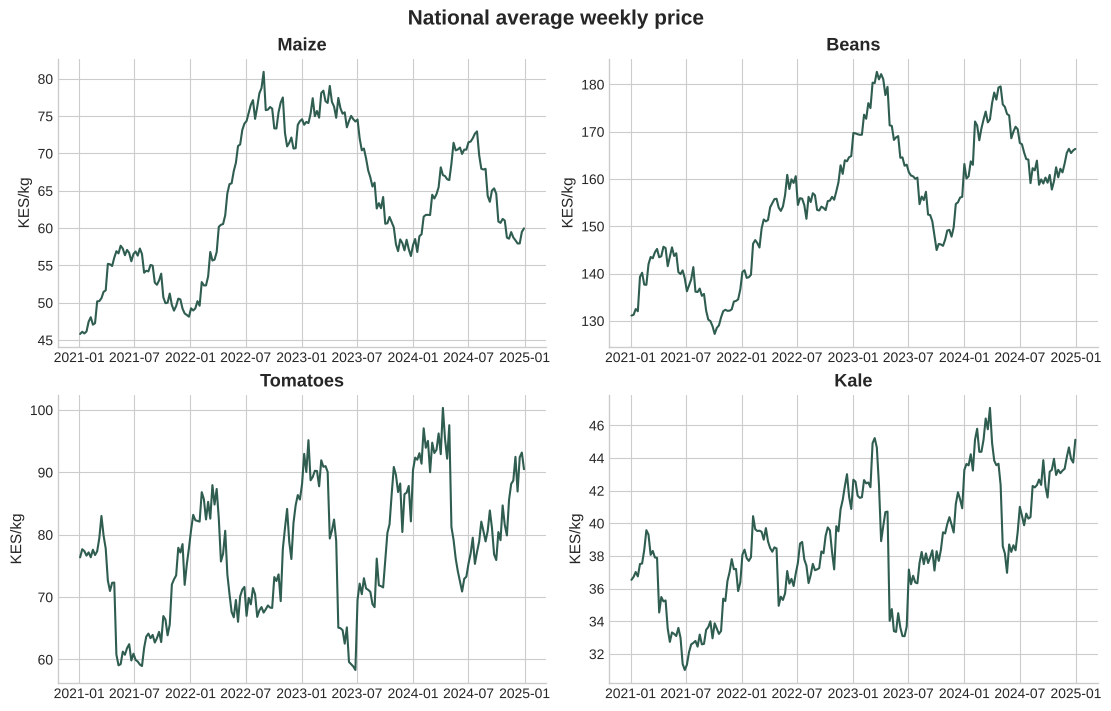

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
crops = ["Maize", "Beans", "Tomatoes", "Kale"]
for ax, crop in zip(axes.flat, crops):                        # axes.flat walks the 2x2 grid as a simple list
    g = prices[prices["crop"] == crop].groupby("date")["price_kes_per_kg"].mean()
    ax.plot(g.index, g.values, color="#2F5D50")
    ax.set_title(crop)
    ax.set_ylabel("KES/kg")
fig.suptitle("National average weekly price", fontsize=15, fontweight="bold")
plt.show()

### Two y-axes with `twinx` (use sparingly!)

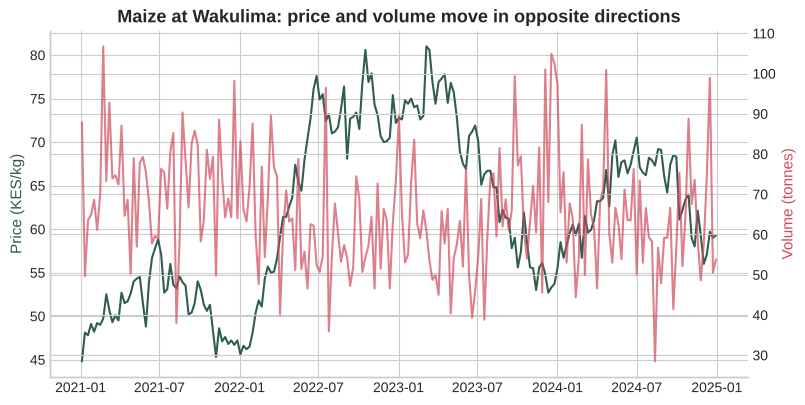

In [14]:
w = prices[(prices["crop"] == "Maize") & (prices["market"] == "Wakulima Market")].sort_values("date")
fig, ax1 = plt.subplots()
ax1.plot(w["date"], w["price_kes_per_kg"], color="#2F5D50", label="Price")
ax1.set_ylabel("Price (KES/kg)", color="#2F5D50")
ax2 = ax1.twinx()
ax2.plot(w["date"], w["volume_kg"] / 1000, color="#d1495b", alpha=0.7, label="Volume")
ax2.set_ylabel("Volume (tonnes)", color="#d1495b")
ax1.set_title("Maize at Wakulima: price and volume move in opposite directions")
plt.show()

> ⚠️ **Common mistake.** Dual axes can *manufacture* correlations: change either axis range and the lines can be made to 'match' or 'diverge' at will. Use them for exploration, but prefer two stacked panels with a shared x-axis for presentation.

### Saving

In [15]:
import tempfile, os
path = os.path.join(tempfile.gettempdir(), "maize_price.png")
fig.savefig(path, dpi=150, bbox_inches="tight")        # dpi=150+ for slides/reports, bbox_inches avoids cropped labels
print("saved:", path, "->", os.path.getsize(path) // 1024, "KB")

saved: /tmp/maize_price.png -> 194 KB


## 8 · Choosing the right chart

| Your question | Chart | Avoid |
|---|---|---|
| How does X change over time? | **line** | bars for dense time series |
| Which category is bigger? | **bar** (sorted, from zero) | pie charts with >3 slices; 3-D anything |
| How is one number distributed? | **histogram** / box / (Lesson 7: KDE) | a bar chart of the mean only |
| Compare distributions across groups | **box plot** / violin | overlapping opaque histograms |
| Are two numbers related? | **scatter** (+ trend line) | dual-axis lines |
| Which combos are high/low? | **heatmap** (Lesson 7) | tables of 200 numbers |

### The chart-quality checklist ✔️
1. **Title states the finding.**  2. **Axes labelled with units.**  3. **Bars start at zero.**  4. **Sorted logically** (not alphabetically by default).
5. **Few colours, used meaningfully** (and colour-blind safe).  6. **Remove clutter** (heavy grids, borders, legends that repeat the title).  7. **One chart = one message.**

Here is the *same data* told two ways. Which one would you trust?

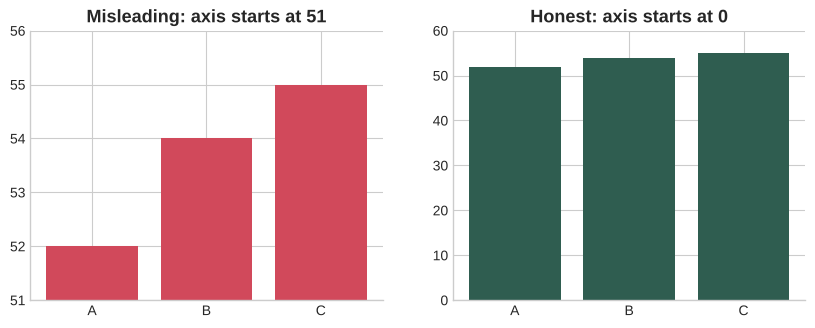

In [16]:
vals = {"A": 52, "B": 54, "C": 55}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(vals.keys(), vals.values(), color="#d1495b"); axes[0].set_ylim(51, 56); axes[0].set_title("Misleading: axis starts at 51")
axes[1].bar(vals.keys(), vals.values(), color="#2F5D50"); axes[1].set_ylim(0, 60); axes[1].set_title("Honest: axis starts at 0")
plt.show()

---
# 🧑‍🏫 Worked examples

## Worked example 1: "Tell the drought story in one chart"

> **Thinking steps.** (1) Decide the message: *"maize got dearer during the drought, then eased."* (2) Pick the chart: a line over time. (3) Aggregate to the **national monthly average** (less noise). (4) Highlight the drought with a shaded band. (5) Title = the message.

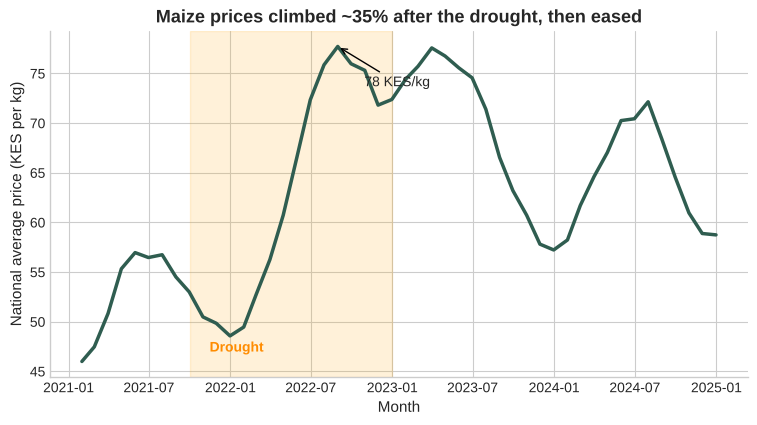

In [17]:
m = (prices[prices["crop"] == "Maize"].set_index("date")["price_kes_per_kg"].resample("ME").mean())

fig, ax = plt.subplots()
ax.plot(m.index, m.values, color="#2F5D50", linewidth=2.5)
ax.axvspan(pd.Timestamp("2021-10-01"), pd.Timestamp("2022-12-31"), color="orange", alpha=0.15)
ax.text(pd.Timestamp("2021-11-15"), m.min() + 1, "Drought", color="darkorange", fontweight="bold")
top = m.idxmax()
ax.annotate(f"{m.max():.0f} KES/kg", xy=(top, m.max()), xytext=(top + pd.Timedelta(days=60), m.max() - 4), arrowprops=dict(arrowstyle="->"))
ax.set_title("Maize prices climbed ~35% after the drought, then eased")
ax.set_xlabel("Month"); ax.set_ylabel("National average price (KES per kg)")
plt.show()

## Worked example 2: A four-panel "profile" of one series

> **Thinking steps.** For any series ask four questions, one panel each: *trend* (line), *shape* (histogram), *relationship* (scatter vs volume), *seasonality/change* (box by year).

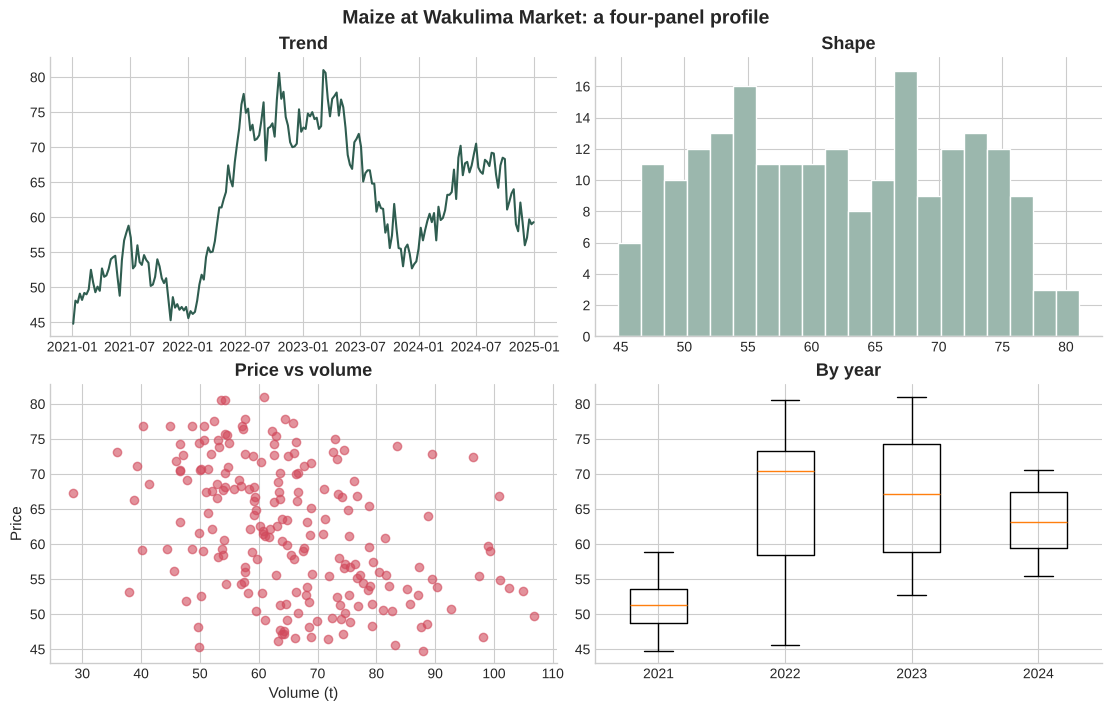

In [18]:
s = prices[(prices["crop"] == "Maize") & (prices["market"] == "Wakulima Market")].sort_values("date")
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)

axes[0, 0].plot(s["date"], s["price_kes_per_kg"], color="#2F5D50"); axes[0, 0].set_title("Trend")
axes[0, 1].hist(s["price_kes_per_kg"], bins=20, color="#9bb7ad", edgecolor="white"); axes[0, 1].set_title("Shape")
axes[1, 0].scatter(s["volume_kg"] / 1000, s["price_kes_per_kg"], alpha=0.6, color="#d1495b"); axes[1, 0].set_title("Price vs volume")
axes[1, 0].set_xlabel("Volume (t)"); axes[1, 0].set_ylabel("Price")
by_year = [s.loc[s["year"] == y, "price_kes_per_kg"] for y in [2021, 2022, 2023, 2024]]
axes[1, 1].boxplot(by_year); axes[1, 1].set_xticklabels([2021, 2022, 2023, 2024]); axes[1, 1].set_title("By year")
fig.suptitle("Maize at Wakulima Market: a four-panel profile", fontsize=14, fontweight="bold")
plt.show()

---
# 🏋️ Problems

For the 🎨 **chart problems**, create the figure so that your **last** `ax` holds the chart, then run the cell: the checker verifies the essentials (title, axis labels, enough lines/bars/points).
Beyond the checker: *look at your chart*. Would a stranger understand it in ten seconds?

### 🎨 Problem 6.1: Maize at Nakuru over time

Draw a **line chart** of the weekly **Maize** price at **Nakuru Municipal Market** against date (sorted by date). Add a title, an x-label and a y-label (with units).

<details>
<summary>💡 Hint 1</summary>

Filter two conditions, then `sort_values('date')` before plotting.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`ax.plot(df['date'], df['price_kes_per_kg'])`, then `ax.set_title`, `ax.set_xlabel`, `ax.set_ylabel`.

</details>

❌ 06-p1: add a title (ax.set_title); label the x-axis (ax.set_xlabel); label the y-axis (ax.set_ylabel); expected 1 line(s) but found 0.


False

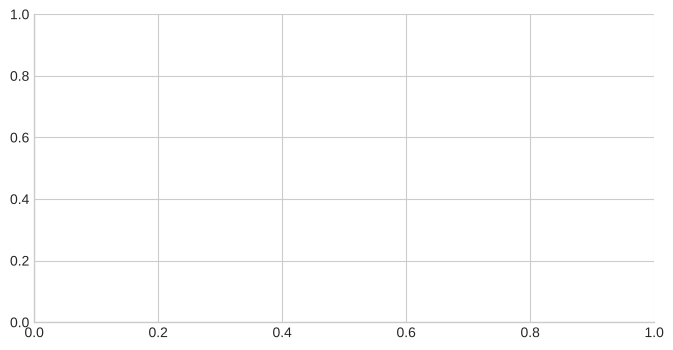

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, n_lines=1, name='06-p1')

### 🎨 Problem 6.2: Three counties, one chart

Plot the **monthly average Tomato price** for **Nairobi, Mombasa and Kisumu** as **three lines** on one chart (legend required, plus title and axis labels).

<details>
<summary>💡 Hint 1</summary>

Filter tomatoes and `county.isin([...])`. Then for each county: `set_index('date')`, `resample('ME').mean()`.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

Loop over `groupby('county')` calling `ax.plot(..., label=county)` and finish with `ax.legend()`.

</details>

❌ 06-p2: add a title (ax.set_title); label the x-axis (ax.set_xlabel); label the y-axis (ax.set_ylabel); expected 3 line(s) but found 0; add a legend (ax.legend or a hue/label argument).


False

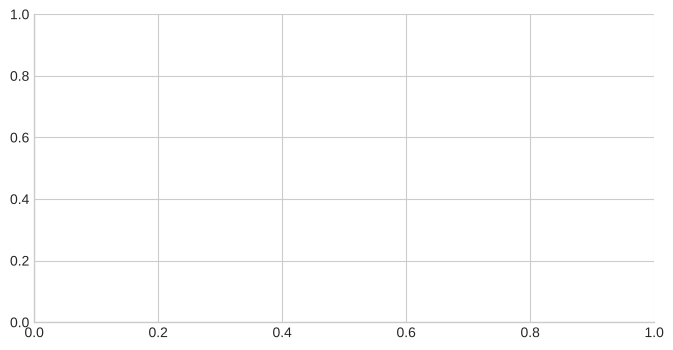

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, n_lines=3, legend=True, name='06-p2')

### 🎨 Problem 6.3: Crop price league table

Draw a **horizontal bar chart** of the **mean price per crop**, sorted from cheapest to dearest, with a title and an x-label.

<details>
<summary>💡 Hint 1</summary>

Compute `prices.groupby('crop')['price_kes_per_kg'].mean().sort_values()`.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`ax.barh(series.index, series.values)`.

</details>

❌ 06-p3: add a title (ax.set_title); label the x-axis (ax.set_xlabel); expected at least 8 bar/patch objects but found 0.


False

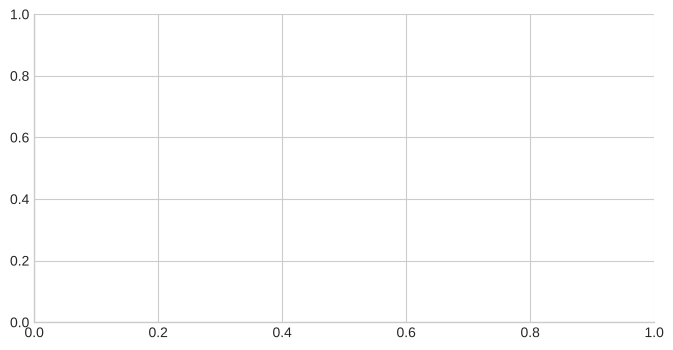

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, min_bars=8, ylabel=False, name='06-p3')

### 🎨 Problem 6.4: Beans: mean vs median

Draw a **histogram (20 bins)** of all **Beans** prices. Add **two vertical lines**: one for the mean, one for the median (different styles), plus title and axis labels.

<details>
<summary>💡 Hint 1</summary>

`ax.hist(series, bins=20)` for the bars.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`ax.axvline(value, linestyle='--')` adds a vertical line (it counts as a line on the axes).

</details>

❌ 06-p4: add a title (ax.set_title); label the x-axis (ax.set_xlabel); label the y-axis (ax.set_ylabel); expected 2 line(s) but found 0; expected at least 20 bar/patch objects but found 0.


False

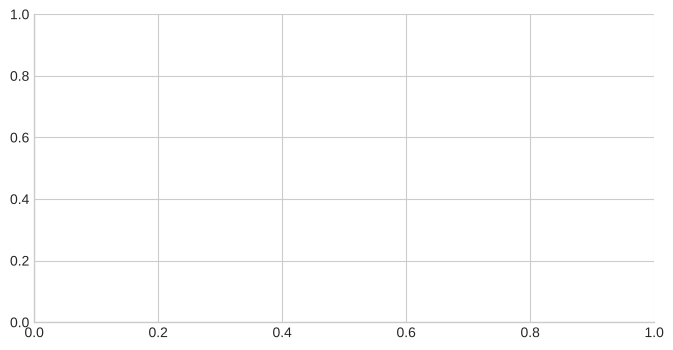

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, n_lines=2, min_bars=20, name='06-p4')

### 🎨 Problem 6.5: Does volume move price?

Draw a **scatter plot** of weekly **volume (tonnes, x)** against **price (KES/kg, y)** for **Tomatoes at Wakulima Market**, with title and axis labels.

<details>
<summary>💡 Hint 1</summary>

Filter two conditions. Convert `volume_kg / 1000` for tonnes.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`ax.scatter(x, y, alpha=0.7)`.

</details>

❌ 06-p5: add a title (ax.set_title); label the x-axis (ax.set_xlabel); label the y-axis (ax.set_ylabel); expected at least 100 scatter points but found 0.


False

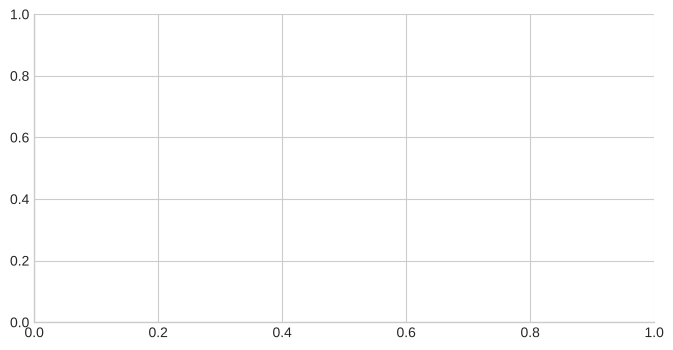

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, min_points=100, name='06-p5')

### 🎨 Problem 6.6: Which crop is most variable?

Draw a **box plot** of price for every crop (one box per crop, in alphabetical order), with the crop names on the x-axis, a title and a y-label.

<details>
<summary>💡 Hint 1</summary>

Build a list of arrays: `[prices.loc[prices['crop']==c, 'price_kes_per_kg'] for c in crops]`.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`ax.boxplot(list_of_arrays)` then `ax.set_xticklabels(crops)`.

</details>

❌ 06-p6: add a title (ax.set_title); label the y-axis (ax.set_ylabel); expected at least 8 line(s) but found 0.


False

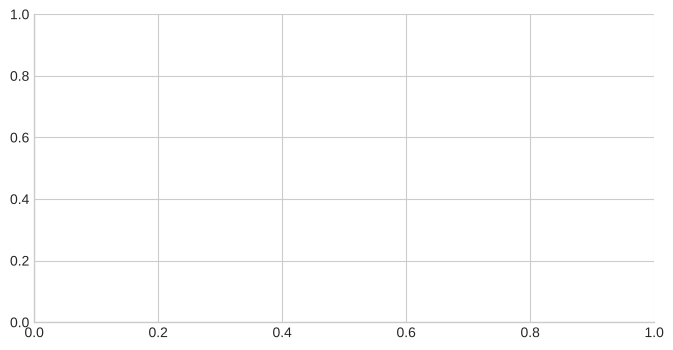

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, min_lines=8, xlabel=False, name='06-p6')

### 🎨 Problem 6.7: A 2×2 dashboard

Create a figure with a **2×2 grid** of axes (`axes`). Fill it with the national weekly average price of **Maize, Beans, Onions, Potatoes** (one crop per panel, line plots). Give **each panel a title** and a y-label. Finally set `ax = axes[1, 1]` so the checker can inspect the last panel.

<details>
<summary>💡 Hint 1</summary>

`fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)`; `axes.flat` iterates over the four panels.

</details>

<details>
<summary>💡 Hint 2</summary>

National weekly average: `prices[prices.crop == crop].groupby('date')['price_kes_per_kg'].mean()`.

</details>

<details>
<summary>💡 Hint 3 (the big nudge)</summary>

After the loop, `ax = axes[1, 1]`: and make sure the loop gave that panel a title, x-label, and y-label too.

</details>

❌ 06-p7: add a title (ax.set_title); label the x-axis (ax.set_xlabel); label the y-axis (ax.set_ylabel); expected 1 line(s) but found 0.


False

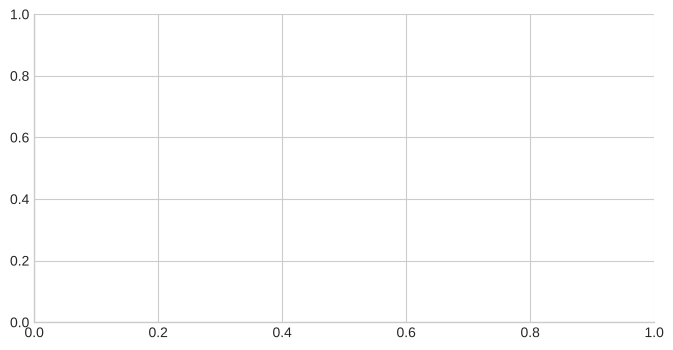

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, n_lines=1, name='06-p7')

### ✍️ Problem 6.8: Critique this chart

Someone shows you a **3-D pie chart** with 8 slices (one per crop) sized by *average price*, a rainbow colour scheme, no title, and no numbers. List **at least four problems**, and say which chart from the guide you would replace it with, and what its title would be.

✍️ *Write your answer here (double-click to edit):*



## ✅ Check your understanding

Answer in your head (or out loud!) first, *then* open the answer.

**Q1. Why use `fig, ax = plt.subplots()` instead of `plt.plot(...)`?**

<details>
<summary>Show answer</summary>

It makes explicit *which* axes you are drawing on, which is essential once you have several panels or need to customise precisely. The OO interface scales; the state-machine interface gets confusing.

</details>

**Q2. A bar chart's y-axis starts at 50 instead of 0. What's the problem?**

<details>
<summary>Show answer</summary>

Bar *length* encodes the value, so truncating the axis exaggerates differences (a 4% gap looks like 4×). Bars should start at zero.

</details>

**Q3. The mean is far to the right of the median in a histogram. What do you conclude?**

<details>
<summary>Show answer</summary>

The distribution is right-skewed: a tail of high values pulls the mean up. The median is a better 'typical' value.

</details>

**Q4. Name two problems with dual-axis charts.**

<details>
<summary>Show answer</summary>

The two scales are arbitrary, so you can make lines appear correlated or not; readers also confuse which line belongs to which axis.

</details>

**Q5. What does a dot beyond a box plot's whisker mean?**

<details>
<summary>Show answer</summary>

A point more than 1.5 × IQR beyond the quartile: a *potential* outlier worth investigating (not automatically an error).

</details>

## 🧾 Cheat-sheet

```python
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(x, y, label="..")            # line            ax.bar(x, h) / ax.barh(y, w)      # bars
ax.hist(v, bins=30)                  # histogram       ax.scatter(x, y, alpha=.6, c=z)   # scatter
ax.boxplot([a, b, c]); ax.set_xticklabels([...])                                          # box plot
ax.axvline(v) / ax.axhline(v) / ax.axvspan(x0, x1, alpha=.15)                             # reference marks
ax.annotate("text", xy=(x, y), xytext=(x2, y2), arrowprops=dict(arrowstyle="->"))
ax.set_title(".."); ax.set_xlabel(".."); ax.set_ylabel(".."); ax.legend()
fig.savefig("chart.png", dpi=150, bbox_inches="tight")
```

## ➡️ Next up
**Lesson 7 (Seaborn.** Everything you did in 10 lines, in one) plus heatmaps, distribution plots, regression lines and multi-panel grids with *statistical* smarts built in.